# Employee Attrition Analysis Project
# Description: This projects focuses on analyzing employee data to identify patterns associated with employee attrition. It focuses on differences across departments and job roles, as well as factors such as burnout, engagement, manager support, overtime, and compensation. These patterns could help an organization determine where further investigation into employee retention might be useful for the overall growth of the organization. 

# This dataset contains 5,000 employee records and 29 variables describing various employee demographics. This dataset is taken from a publicly available dataset (via Kaggle) and does not contain real employee information. 

In [1]:
import pandas
import matplotlib.pyplot as plt

employees = pandas.read_csv("employee_attrition_hr_2026.csv")
employees.head()


,employee_id,age,gender,marital_status,education_level,department,job_role,job_level,monthly_income,stock_option_level,...,training_hours,manager_support_score,burnout_score,engagement_score,work_life_balance_score,performance_rating,last_review_score,uses_ai_tools_at_work,perceived_ai_job_risk,attrition
0,1001,37,Male,Divorced,Masters,Engineering,Engineering Manager,3,7365,0,...,17,9.4,1.0,9.7,7.7,3,8.3,True,4.8,No
1,1002,24,Female,Married,Bachelors,Finance,Finance Manager,2,4746,2,...,21,4.2,1.9,5.4,7.8,3,8.0,True,2.9,Yes
2,1003,24,Female,Single,Bachelors,Marketing,Marketing Specialist,1,2740,2,...,22,7.5,5.3,6.5,7.0,4,9.5,True,7.2,No
3,1004,44,Male,Single,Bachelors,Sales,Sales Manager,4,7334,1,...,21,8.7,4.3,7.3,3.5,4,7.9,False,5.2,No
4,1005,37,Female,Divorced,Bachelors,Sales,Sales Development Rep,3,9096,0,...,20,7.5,2.3,7.0,7.2,4,8.5,False,6.4,No


In [2]:
employees.shape

(5000, 29)

In [3]:
employees.info() # to see how complete the data is 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 29 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   employee_id                    5000 non-null   int64  
 1   age                            5000 non-null   int64  
 2   gender                         5000 non-null   object 
 3   marital_status                 5000 non-null   object 
 4   education_level                5000 non-null   object 
 5   department                     5000 non-null   object 
 6   job_role                       5000 non-null   object 
 7   job_level                      5000 non-null   int64  
 8   monthly_income                 5000 non-null   int64  
 9   stock_option_level             5000 non-null   int64  
 10  salary_hike_pct                5000 non-null   float64
 11  years_at_company               5000 non-null   float64
 12  total_working_years            5000 non-null   f

In [4]:
employees.isnull().sum() # No missing values were identified

employee_id                      0
age                              0
gender                           0
marital_status                   0
education_level                  0
department                       0
job_role                         0
job_level                        0
monthly_income                   0
stock_option_level               0
salary_hike_pct                  0
years_at_company                 0
total_working_years              0
years_since_promotion            0
num_prior_companies              0
work_mode                        0
commute_minutes                  0
overtime_hours_per_week          0
business_travel_days_per_year    0
training_hours                   0
manager_support_score            0
burnout_score                    0
engagement_score                 0
work_life_balance_score          0
performance_rating               0
last_review_score                0
uses_ai_tools_at_work            0
perceived_ai_job_risk            0
attrition           

# I established a baseline attrition rate to understand the overall distribution of employees who stayed versus those who left.

In [5]:
employees["attrition"].value_counts()

attrition
No     4105
Yes     895
Name: count, dtype: int64

In [6]:
employees["attrition"].value_counts(normalize=True)* 100

attrition
No     82.1
Yes    17.9
Name: proportion, dtype: float64

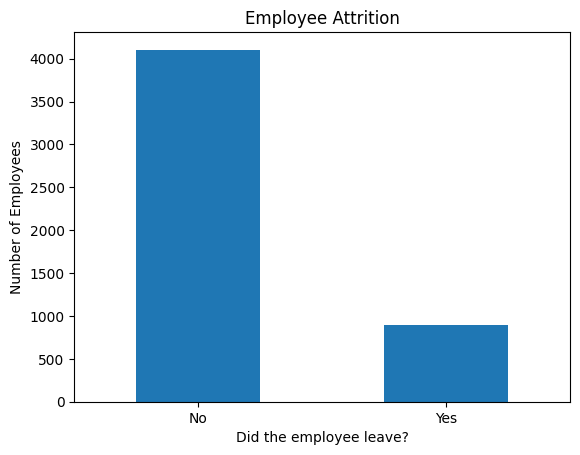

In [7]:
attrition_counts = employees["attrition"].value_counts()
attrition_counts.plot(kind="bar")

# 895 employees left the company out of 5,000, representing 17.9% of the dataset
plt.title("Employee Attrition")
plt.xlabel("Did the employee leave?")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.show()

# Does attrition vary across departments? The attrition rate was calculated as the percentage of employees within each department who were recorded as having left the company. 

In [8]:
department_attrition = pandas.crosstab(
    employees["department"],
    employees["attrition"],
    normalize="index"
) * 100

department_attrition["Yes"].sort_values(ascending=False)

department
Customer Support          24.056604
Sales                     20.000000
Marketing                 18.863636
Finance                   18.119266
Human Resources           18.032787
Operations                17.194570
Research & Development    14.878049
Engineering               14.520958
Name: Yes, dtype: float64

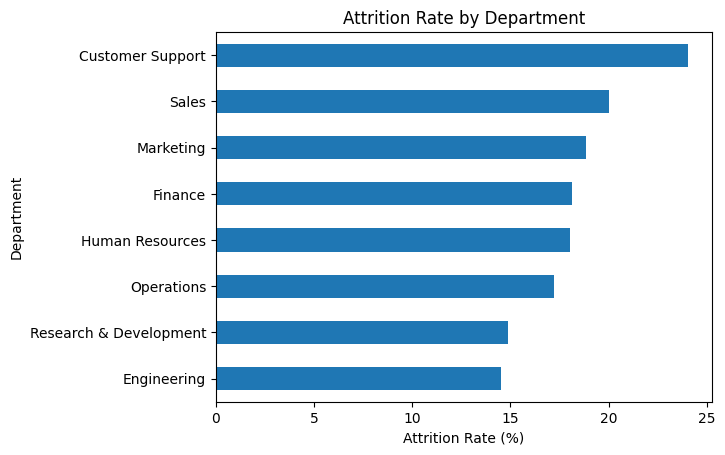

In [9]:
department_attrition["Yes"].sort_values().plot(kind="barh")
plt.title("Attrition Rate by Department")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Department")
plt.show()

# Attrition varied across departments. Customer Support had the highest observed attrition rate at approximately 24.1%, while Engineering had the lowest attrition rate at approximately 14.5%. 
# Department level factors might be worth investigating further when examining employee retention due to this difference in attrition rate.

# Does attrition vary across job roles?

In [10]:
job_role_attrition = pandas.crosstab(
    employees["job_role"],
    employees["attrition"],
    normalize="index"
) * 100

job_role_attrition["Yes"].sort_values(ascending=False)

job_role
Support Team Lead           25.980392
Support Specialist          25.229358
Content Strategist          23.913043
Account Executive           23.826715
Recruiter                   23.188406
Customer Success Manager    21.028037
Finance Manager             20.863309
Sales Development Rep       20.077220
Growth Manager              19.871795
Financial Analyst           19.580420
Research Scientist          18.987342
Operations Manager          18.181818
HR Manager                  17.021277
Program Manager             16.901408
Operations Analyst          16.438356
Sales Manager               16.387960
QA Engineer                 16.207951
Engineering Manager         15.606936
HR Business Partner         14.814815
Product Researcher          14.393939
Accountant                  14.285714
Data Engineer               14.018692
Marketing Specialist        13.013699
Software Engineer           12.280702
R&D Manager                 10.000000
Name: Yes, dtype: float64

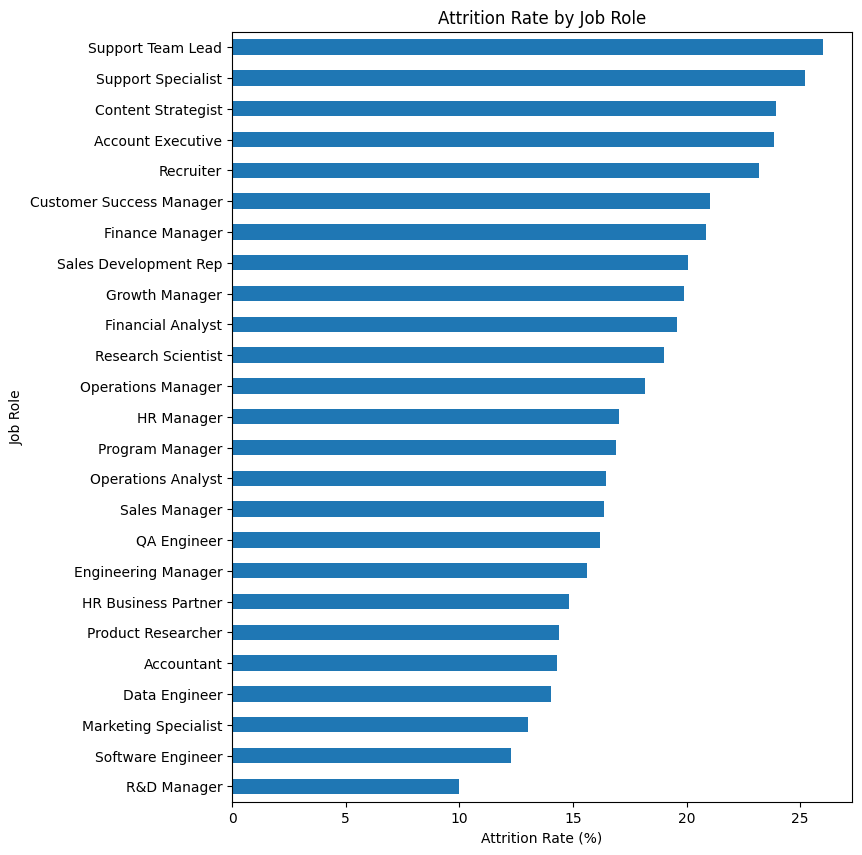

In [11]:
job_role_attrition["Yes"].sort_values().plot(kind="barh", figsize=(8,10))

plt.title("Attrition Rate by Job Role")
plt.xlabel("Attrition Rate (%)")
plt.ylabel("Job Role")
plt.show()

# Similar to attrition across departments, the attrition rate across job roles also varied. Many support and customer-facing roles showed higher attrition rates than many technical and engineering roles.
# These results can be viewed as areas for further investigation because these job roles differ in responsibilities and workload.

# How does burnout, engagement, and manager support affect the employee attrition rate?

In [12]:
employees.groupby("attrition")[[
    "burnout_score",
    "engagement_score",
    "manager_support_score"
]].mean()

,burnout_score,engagement_score,manager_support_score
attrition,,,
No,3.809574,6.719537,6.814982
Yes,5.059777,5.537654,5.689385


In [13]:
employees["burnout_level"] = pandas.cut(
    employees["burnout_score"],
    bins=[0, 3, 5, 7, 10],
    labels=["Low", "Moderate", "High", "Very High"]
)

employees["engagement_level"] = pandas.cut(
    employees["engagement_score"],
    bins=[0, 3, 5, 7, 10],
    labels=["Low", "Moderate", "High", "Very High"]
)

employees["manager_support_level"] = pandas.cut(
    employees["manager_support_score"],
    bins=[0, 3, 5, 7, 10],
    labels=["Low", "Moderate", "High", "Very High"]
)

# turning decimal values into groups to make a better comparison 

In [14]:
burnout_attrition = pandas.crosstab(
    employees["burnout_level"],
    employees["attrition"],
    normalize="index"
) * 100

burnout_attrition["Yes"].sort_values()

burnout_level
Low           4.646018
Moderate     16.728625
High         32.015066
Very High    54.037267
Name: Yes, dtype: float64

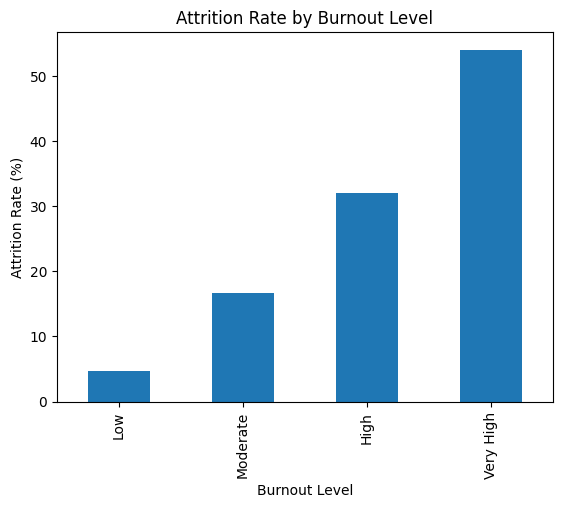

In [15]:
burnout_attrition["Yes"].sort_values().plot(kind="bar")

plt.title("Attrition Rate by Burnout Level")
plt.xlabel("Burnout Level")
plt.ylabel("Attrition Rate (%)")
plt.show()

In [16]:
engagement_attrition = pandas.crosstab(
    employees["engagement_level"],
    employees["attrition"],
    normalize="index"
) * 100

engagement_attrition["Yes"].sort_values()

engagement_level
Very High     6.909684
High         19.504908
Moderate     36.435125
Low          58.928571
Name: Yes, dtype: float64

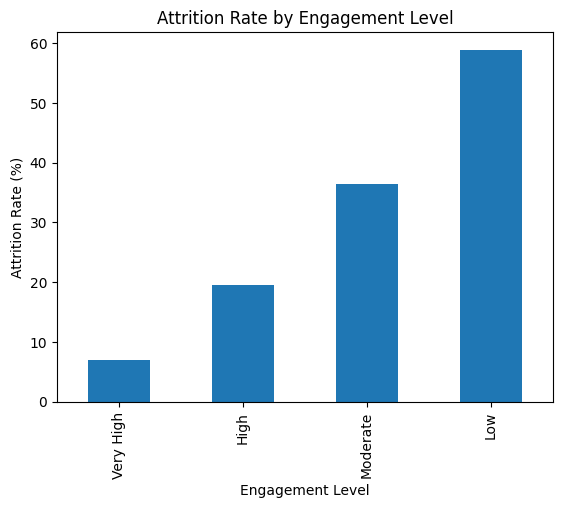

In [17]:
engagement_attrition["Yes"].sort_values().plot(kind="bar")

plt.title("Attrition Rate by Engagement Level")
plt.xlabel("Engagement Level")
plt.ylabel("Attrition Rate (%)")
plt.show()

In [18]:
manager_support_attrition = pandas.crosstab(
    employees["manager_support_level"],
    employees["attrition"],
    normalize="index"
) * 100

manager_support_attrition["Yes"].sort_values()

manager_support_level
Very High    10.108644
High         18.812931
Moderate     30.622010
Low          43.750000
Name: Yes, dtype: float64

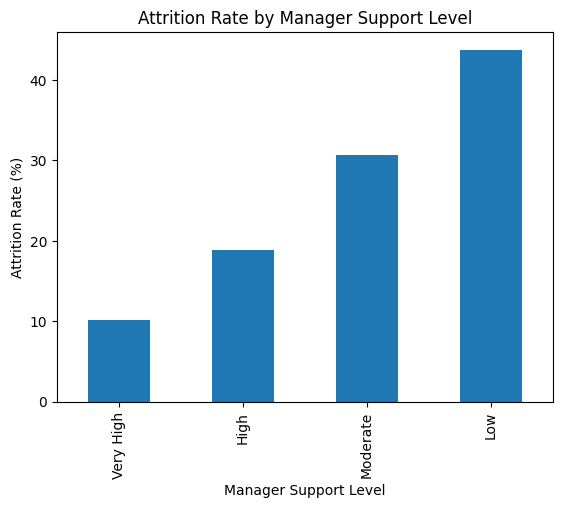

In [19]:
manager_support_attrition["Yes"].sort_values().plot(kind="bar")

plt.title("Attrition Rate by Manager Support Level")
plt.xlabel("Manager Support Level")
plt.ylabel("Attrition Rate (%)")
plt.show()

# The data shows a strong relationship between employee experience and observed attrition. Employees in higher burnout categories had higher attrition rates, while employees in lower engagement and manager support categories also showed higher attrition rates. 

# Does workload and compensation affect attrition rate?

In [20]:
employees.groupby("attrition")[[
    "overtime_hours_per_week",
    "monthly_income"
]].mean()

,overtime_hours_per_week,monthly_income
attrition,,
No,6.404409,7059.544945
Yes,8.772067,6675.046927


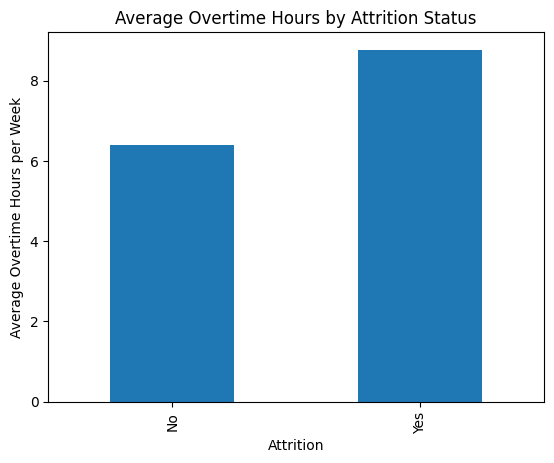

In [21]:
employees.groupby("attrition")["overtime_hours_per_week"].mean().plot(kind="bar")

plt.title("Average Overtime Hours by Attrition Status")
plt.xlabel("Attrition")
plt.ylabel("Average Overtime Hours per Week")
plt.show()

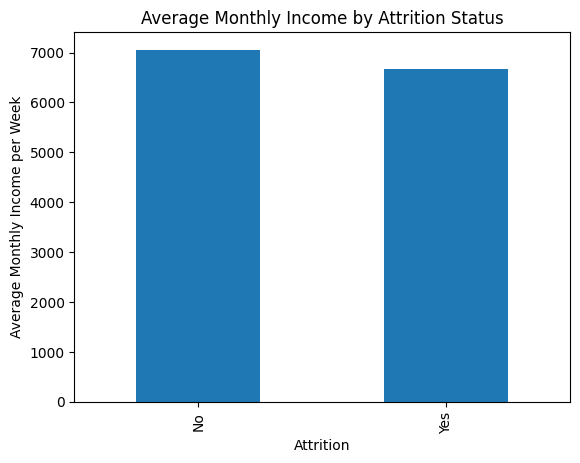

In [ ]:
employees.groupby("attrition")["monthly_income"].mean().plot(kind="bar")

plt.title("Average Monthly Income by Attrition Status")
plt.xlabel("Attrition")
plt.ylabel("Average Monthly Income per Week")
plt.show()


# Employees who left averaged approximately 8.8 hours of overtime per week, compared with approximately 6.4 hours of overtime among employees who stayed.Employees who left also had a lower average monthly income in this dataset. Workload and compensation are additional areas that could be examined in more detail.

# This analysis identifies several areas that could be further investigated, such as workload, overtime patterns in departments with higher attrition. Another area that could be employee engagement and burnout among higher-risk groups. While the results don't establish causal relationships, they could still be used for additional investigation regarding employee turnover.

# The data was loaded into a SQLite database to get some initial findings about the data.

In [ ]:
import sqlite3
conn = sqlite3.connect("employee_attrition.db")
employees.to_sql(
    "employees",
    conn,
    if_exists="replace",
    index=False
)


5000

In [30]:
query = """
SELECT COUNT(*) AS total_employees,
SUM(CASE WHEN attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
ROUND(
    100.0 * SUM(CASE WHEN attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
    2
) AS attrition_rate
FROM employees;
"""

pandas.read_sql_query(query, conn)

,total_employees,employees_left,attrition_rate
0,5000,895,17.9


In [ ]:
# department & attrition 
query = """
SELECT department, COUNT(*) AS total_employees, 
SUM(CASE WHEN attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
ROUND(
    100.0 * SUM(CASE WHEN attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
    2 
) AS attrition_rate
FROM employees
GROUP BY department
ORDER BY attrition_rate DESC;
"""

pandas.read_sql_query(query, conn)

,department,total_employees,employees_left,attrition_rate
0,Customer Support,636,153,24.06
1,Sales,835,167,20.00
2,Marketing,440,83,18.86
3,Finance,436,79,18.12
4,Human Resources,244,44,18.03
5,Operations,663,114,17.19
6,Research & Development,410,61,14.88
7,Engineering,1336,194,14.52


In [ ]:
# job role & attrition 
query = """
SELECT job_role, COUNT(*) AS total_employees, 
SUM(CASE WHEN attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
ROUND(
    100.0 * SUM(CASE WHEN attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
    2 
) AS attrition_rate
FROM employees
GROUP BY job_role
HAVING COUNT(*) >= 50
ORDER BY attrition_rate DESC;
"""

pandas.read_sql_query(query, conn)

,job_role,total_employees,employees_left,attrition_rate
0,Support Team Lead,204,53,25.98
1,Support Specialist,218,55,25.23
2,Content Strategist,138,33,23.91
3,Account Executive,277,66,23.83
4,Recruiter,69,16,23.19
5,Customer Success Manager,214,45,21.03
6,Finance Manager,139,29,20.86
7,Sales Development Rep,259,52,20.08
8,Growth Manager,156,31,19.87
9,Financial Analyst,143,28,19.58


In [ ]:
# employees who stayed vs left compared with avg burnout score, engagement score, manager support score, overtime, monthly income 
query = """
SELECT attrition, COUNT(*) AS employees,
ROUND(AVG(burnout_score), 2) AS avg_burnout,
ROUND(AVG(engagement_score), 2) AS avg_engagement,
ROUND(AVG(manager_support_score), 2) AS avg_manager_support,
ROUND(AVG(overtime_hours_per_week), 2) AS avg_overtime,
ROUND(AVG(monthly_income), 2) AS avg_monthly_income
FROM employees
GROUP BY attrition;
"""

pandas.read_sql_query(query, conn)

,attrition,employees,avg_burnout,avg_engagement,avg_manager_support,avg_overtime,avg_monthly_income
0,No,4105,3.81,6.72,6.81,6.40,7059.54
1,Yes,895,5.06,5.54,5.69,8.77,6675.05


In [ ]:
# observed attrition across burnout levels
query = """
SELECT CASE
    WHEN burnout_score < 3 THEN 'Low'
    WHEN burnout_score < 5 THEN 'Moderate'
    WHEN burnout_score < 7 THEN 'High'
    ELSE 'Very High'
END AS burnout_level,
COUNT(*) AS total_employees,
SUM(CASE WHEN attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
ROUND(
    100.0 * SUM(CASE WHEN attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
    2
) AS attrition_rate
FROM employees
GROUP BY burnout_level
ORDER BY
    CASE burnout_level
        WHEN 'Low' THEN 1
        WHEN 'Moderate' THEN 2
        WHEN 'High' THEN 3
        WHEN 'Very High' THEN 4
    END;
"""

pandas.read_sql_query(query, conn)

,burnout_level,total_employees,employees_left,attrition_rate
0,Low,1356,63,4.65
1,Moderate,2421,405,16.73
2,High,1062,340,32.02
3,Very High,161,87,54.04


In [37]:
# observed attrition across engagement levels
query = """
SELECT CASE
    WHEN engagement_score < 3 THEN 'Low'
    WHEN engagement_score < 5 THEN 'Moderate'
    WHEN engagement_score < 7 THEN 'High'
    ELSE 'Very High'
END AS engagement_level,
COUNT(*) AS total_employees,
SUM(CASE WHEN attrition = 'Yes' THEN 1 ELSE 0 END) AS employees_left,
ROUND(
    100.0 * SUM(CASE WHEN attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
    2
) AS attrition_rate
FROM employees
GROUP BY engagement_level
ORDER BY
    CASE engagement_level
        WHEN 'Low' THEN 1
        WHEN 'Moderate' THEN 2
        WHEN 'High' THEN 3
        WHEN 'Very High' THEN 4
    END;
"""

pandas.read_sql_query(query, conn)

,engagement_level,total_employees,employees_left,attrition_rate
0,Low,56,33,58.93
1,Moderate,763,278,36.44
2,High,2343,457,19.50
3,Very High,1838,127,6.91


In [38]:
# how attrition, burnout, engagement, and overtime vary across departments?
query = """
SELECT department, COUNT(*) AS total_employees,
ROUND (
    100.0 * SUM(CASE WHEN attrition = 'Yes' THEN 1 ELSE 0 END) / COUNT(*),
    2
) as attrition_rate,
ROUND(AVG(burnout_score), 2) AS avg_burnout,
ROUND(AVG(engagement_score), 2) AS avg_engagement,
ROUND(AVG(overtime_hours_per_week), 2) AS avg_overtime
FROM employees
GROUP BY department
ORDER BY attrition_rate DESC;
"""

pandas.read_sql_query(query,conn)

,department,total_employees,attrition_rate,avg_burnout,avg_engagement,avg_overtime
0,Customer Support,636,24.06,4.37,6.37,7.80
1,Sales,835,20.00,4.39,6.37,8.48
2,Marketing,440,18.86,4.07,6.52,6.72
3,Finance,436,18.12,3.96,6.56,6.31
4,Human Resources,244,18.03,3.94,6.47,6.22
5,Operations,663,17.19,3.99,6.45,6.18
6,Research & Development,410,14.88,3.76,6.63,6.23
7,Engineering,1336,14.52,3.78,6.64,6.15


# 